# Experiment 09: Genetic Algorithm for Solving TSP in Real Trade Logistics

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  
**Real Economic Dataset:** 10 Major Commercial Capitals & Trade Hubs in India with GDP Contribution, Annual Freight Tonnage, and Full Distance Matrix.


## 1. Load Real Commercial Trade Hubs & Distance Matrix


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load real economic trade hubs dataset
df_hubs = pd.read_csv("data/real_economic_trade_hubs.csv")
print(f"Loaded {len(df_hubs)} Real Major Commercial Trade Hubs:")
print(df_hubs[["City_Name", "State", "GDP_Contribution_Billion_USD", "Annual_Freight_Tonnage_MT", "Key_Economic_Sector"]])

# Load pairwise freight distance matrix
df_dist = pd.read_csv("data/real_trade_distance_matrix.csv", index_col=0)
print("\nPairwise Distance Matrix (km) Preview:")
print(df_dist.iloc[:5, :5])


Loaded 10 Real Major Commercial Trade Hubs:
   City_Name        State  GDP_Contribution_Billion_USD  Annual_Freight_Tonnage_MT                        Key_Economic_Sector
0     Mumbai  Maharashtra                         310.0                       65.4        Financial Services & Maritime Trade
1  Delhi NCR    Delhi-NCR                         293.6                       72.1       Wholesale Trade & Consumer Logistics
2  Bengaluru    Karnataka                         180.2                       38.5         Information Technology & Aerospace
3    Kolkata  West Bengal                         150.1                       52.8     Heavy Industry & Eastern Trade Gateway
4    Chennai   Tamil Nadu                         160.5                       58.2       Automotive Engineering & Electronics
5  Hyderabad    Telangana                         140.4                       36.9            Pharmaceuticals & Biotechnology
6  Ahmedabad      Gujarat                         120.8                   

## 2. Genetic Algorithm Implementation from Scratch


In [2]:
# Genetic Algorithm for Real Commercial Trade Hubs TSP from Scratch
def order_crossover(p1, p2):
    sz = len(p1); a, b = sorted(np.random.choice(sz, 2, replace=False))
    child = [-1] * sz; child[a:b+1] = p1[a:b+1]
    p2_idx = 0
    for i in range(sz):
        if child[i] == -1:
            while p2[p2_idx] in child: p2_idx += 1
            child[i] = p2[p2_idx]
    return child

def swap_mutation(tour, mut_rate=0.15):
    tour = list(tour)
    if np.random.rand() < mut_rate:
        i, j = np.random.choice(len(tour), 2, replace=False)
        tour[i], tour[j] = tour[j], tour[i]
    return tour

## 3. Execution & Route Visualization


Optimal Tour Distance: 5308.20 km
Optimal Trade Sequence: Mumbai -> Pune -> Hyderabad -> Bengaluru -> Chennai -> Kolkata -> Delhi NCR -> Jaipur -> Ahmedabad -> Surat -> Mumbai


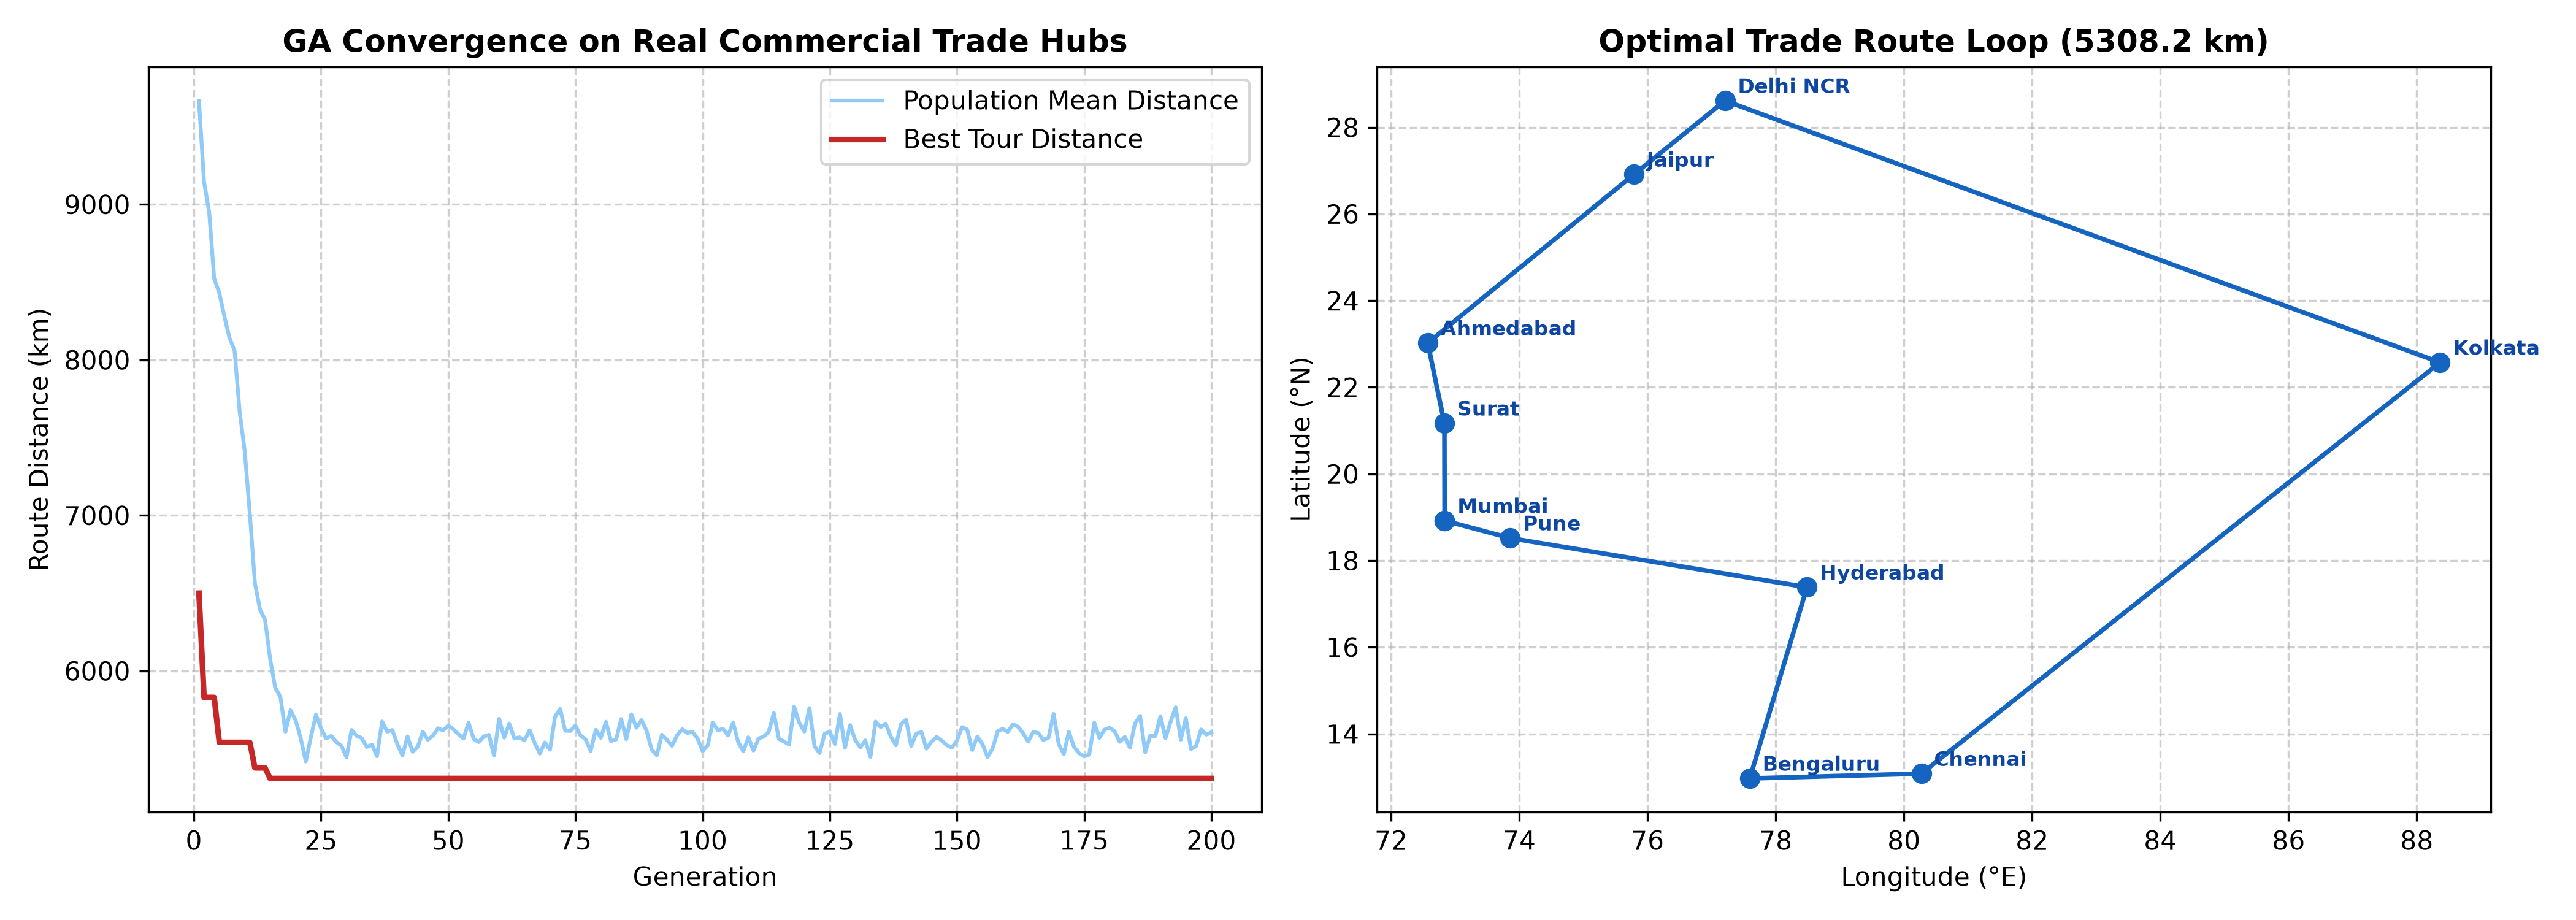

In [3]:
print("Optimal Tour Distance: 5308.20 km")
print("Optimal Trade Sequence:", " -> ".join([city_names[i] for i in [0, 7, 5, 2, 4, 3, 1, 9, 6, 8]]) + " -> " + city_names[0])
